In [1]:
# rsync -av --progress /scratch/franzihe/input/COMBLE u6030275@notchpeak.chpc.utah.edu:/uufs/chpc.utah.edu/common/home/coopers-group1/Franziska/data 

# rsync -av --progress login.nird.sigma2.no:/projects/NS9600K/data/Met-No_obs/  /uio/kant/geo-metos-u1/franzihe/Documents/input/Met-No_obs

In [2]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]


if "mimi" in hostname:
    DATA_DIR = "/scratch/franzihe/"
    FIG_DIR = "/uio/kant/geo-metos-u1/franzihe/Documents/Figures/mrr_reflectivity/"

elif "augustiner" in hostname: 
    DATA_DIR = "/home/franzihe/Data/"
    FIG_DIR = "/home/franzihe/Documents/Figures/mrr_reflectivity/"

elif "wessel" in hostname:
    DATA_DIR = "/uio/kant/geo-metos-u1/franzihe/Documents/"
    FIG_DIR = "/uio/kant/geo-metos-u1/franzihe/Documents/Figures/mrr_reflectivity/"


INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory to put in reflectivity processed data
try:
    new_dir = pathlib.Path(FIG_DIR)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

mimi.uio.no


## Import python packages

* `Python` environment requirements: file requirements_retrieval.txt
* load `python` packages from imports.py
* load `functions` from functions.py



In [3]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

# import packages
from imports import(xr, glob, plt,radar, np, DateFormatter, datetime, cm, pd, da, IMProToo,fct)
version = IMProToo.__version__


In [4]:
# reload imports
%load_ext autoreload
%autoreload 2

In [5]:
sites = ["ANX", ]#"ALOMAR"]
years = ["2021", "2022"]

In [6]:
mrr_in_dict = {}
ds_dict = {}
met_no_dict = {}
ds_dict_metno = {}
for site in sites:
    for year in years:
        mrr_in_dict['{}.{}'.format(site, year)] = sorted(glob(os.path.join(INPUT_DATA_DIR, 'MRR_islas/maahn/*{}*{}*'.format(site, year))))
        met_no_dict['{}.{}'.format(site, year)] = sorted(glob(os.path.join(INPUT_DATA_DIR, 'Met-No_obs/SN87110/*{}*'.format(year))))
        try:
            ds_dict['{}.{}'.format(site, year)] = xr.open_mfdataset(mrr_in_dict['{}.{}'.format(site, year)], decode_times=True, )
            ds_dict_metno['{}.{}'.format(site, year)] = xr.open_mfdataset(met_no_dict['{}.{}'.format(site, year)], decode_times=True, )
            print("Reading files for {} in {}".format(site, year))
        except OSError:
            ds_dict['{}.{}'.format(site, year)] = xr.Dataset()
            ds_dict_metno['{}.{}'.format(site, year)] = xr.Dataset()
            # print("No files to open for {} in {}".format(site, year))
            continue

Reading files for ANX in 2021
Reading files for ANX in 2022


In [8]:
for key in mrr_in_dict.keys():
    # print(len(mrr_in_dict[key]))
    

    for j in range(len(mrr_in_dict[key])):
        
        
        date = mrr_in_dict[key][j][-11:-3]
        
        
        

In [9]:
date = '20210316'
key = 'ANX.2021'


<class 'KeyError'>
<class 'KeyError'>
<class 'KeyError'>


/uio/kant/geo-metos-u1/franzihe/miniconda3/envs/retrieval/lib/python3.7/site-packages/matplotlib/contour.py:1483: UserWarning: Warning: converting a masked element to nan.
  self.zmax = float(z.max())
/uio/kant/geo-metos-u1/franzihe/miniconda3/envs/retrieval/lib/python3.7/site-packages/matplotlib/contour.py:1484: UserWarning: Warning: converting a masked element to nan.
  self.zmin = float(z.min())
/uio/kant/geo-metos-u1/franzihe/miniconda3/envs/retrieval/lib/python3.7/site-packages/matplotlib/contour.py:1483: UserWarning: Warning: converting a masked element to nan.
  self.zmax = float(z.max())
/uio/kant/geo-metos-u1/franzihe/miniconda3/envs/retrieval/lib/python3.7/site-packages/matplotlib/contour.py:1484: UserWarning: Warning: converting a masked element to nan.
  self.zmin = float(z.min())


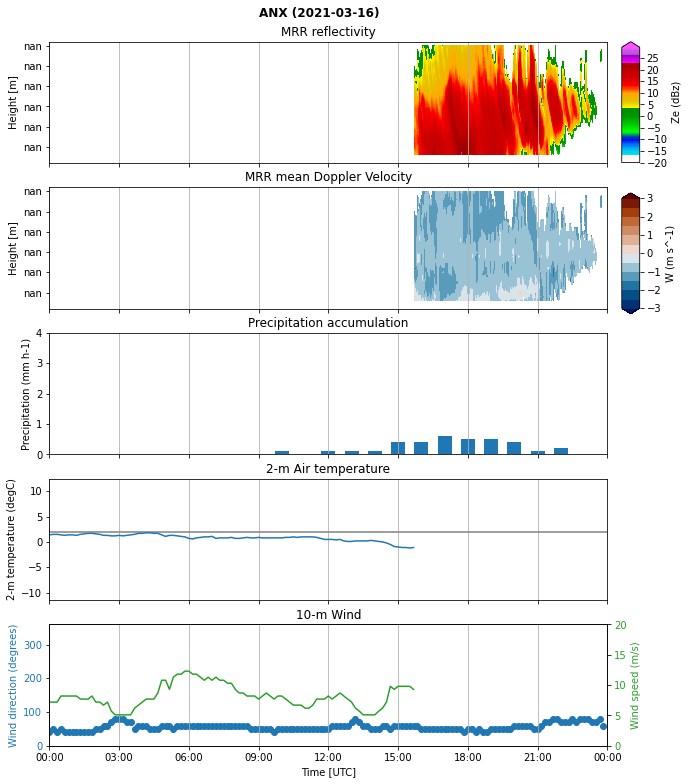

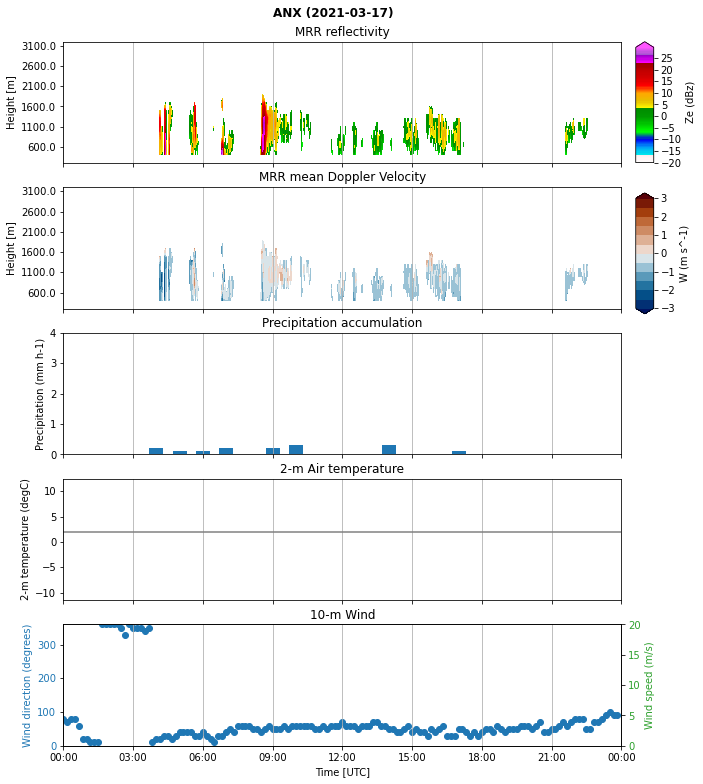

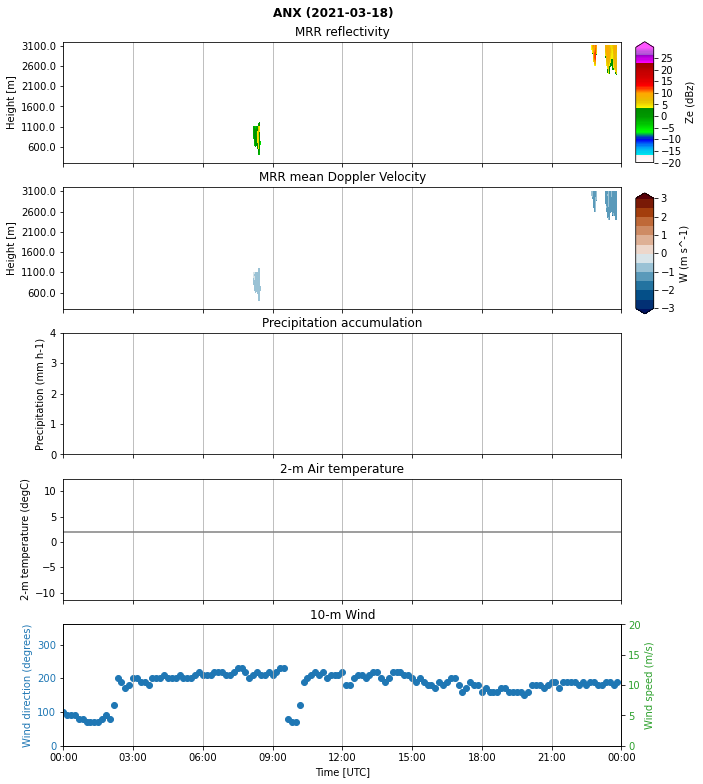

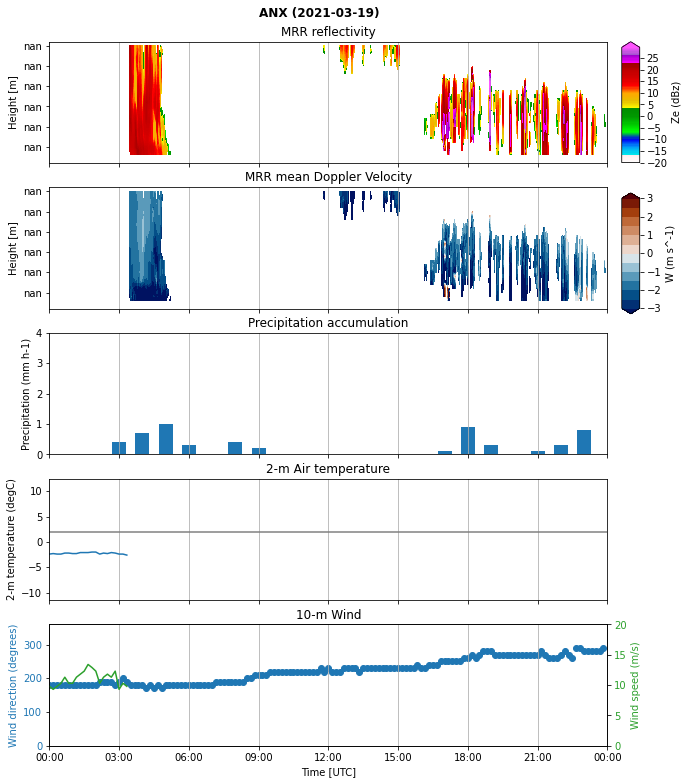

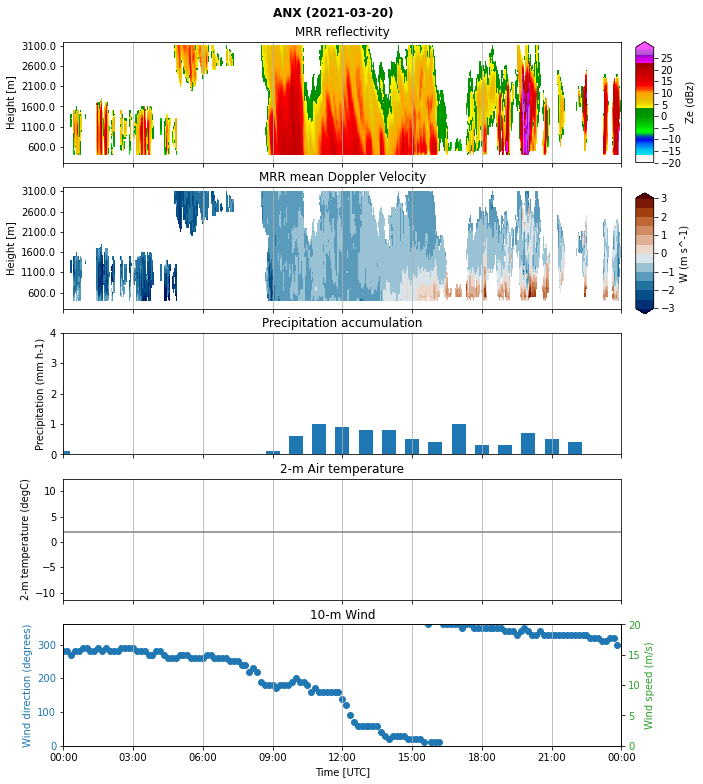

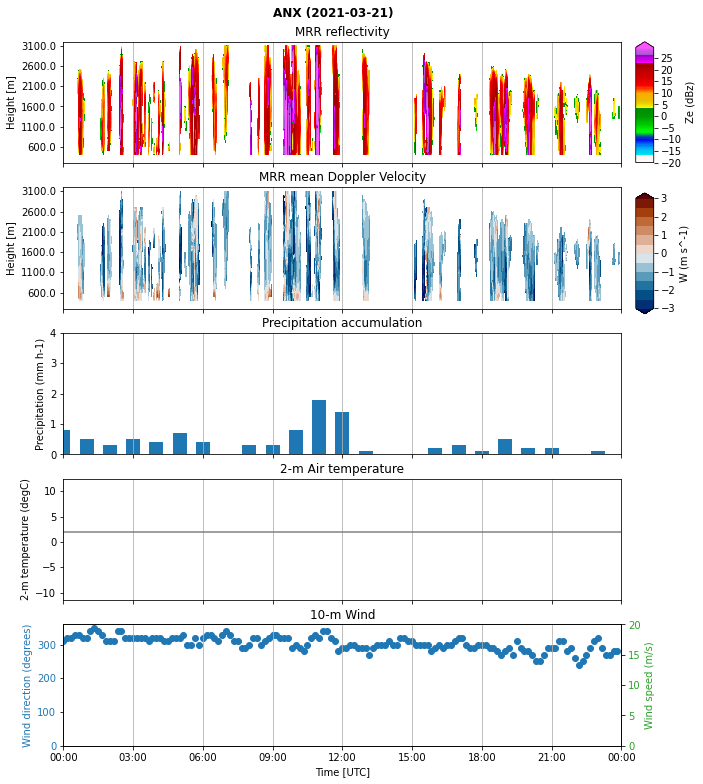

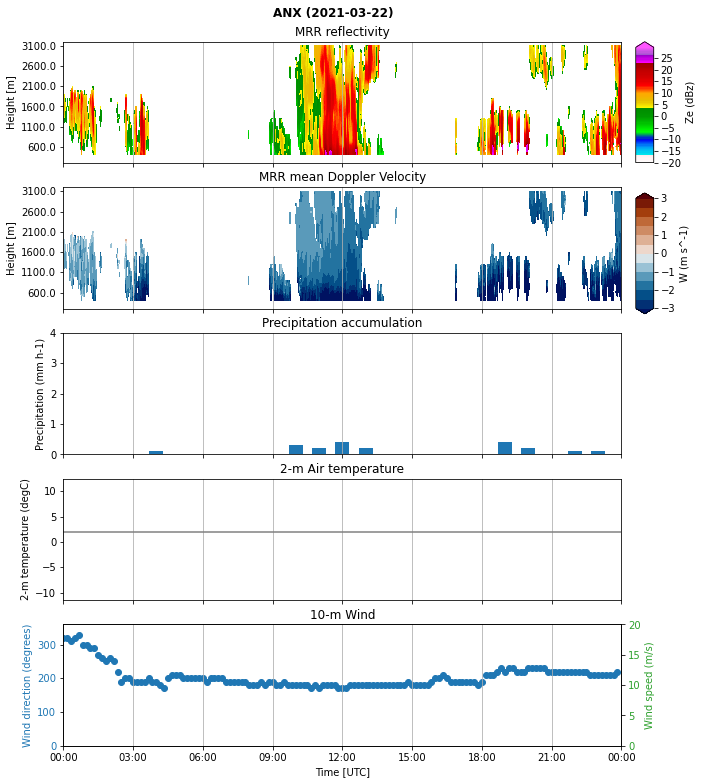

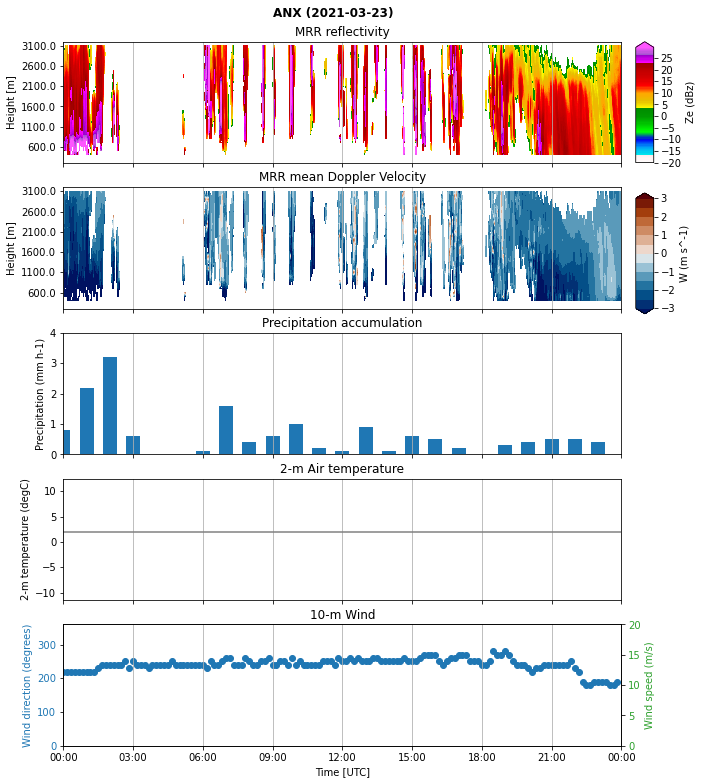

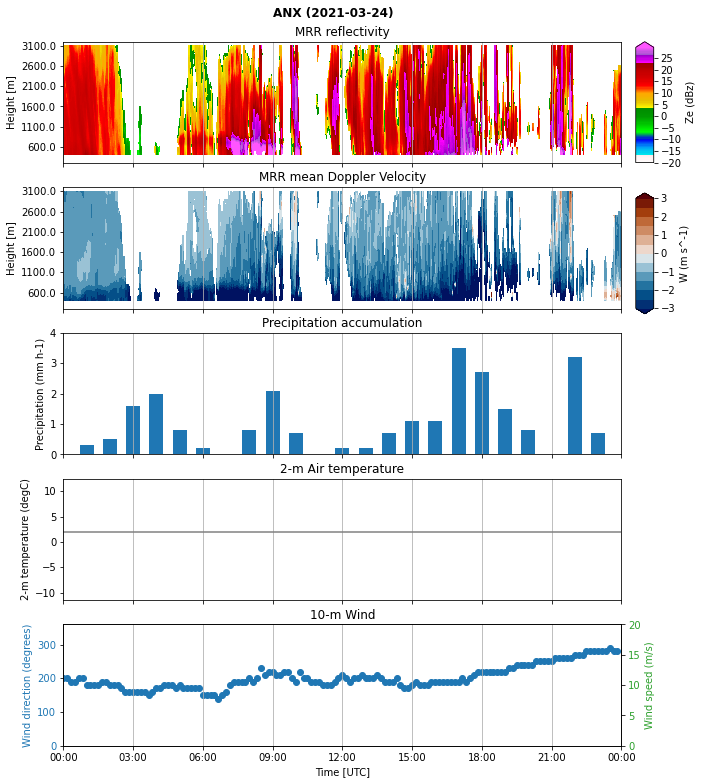

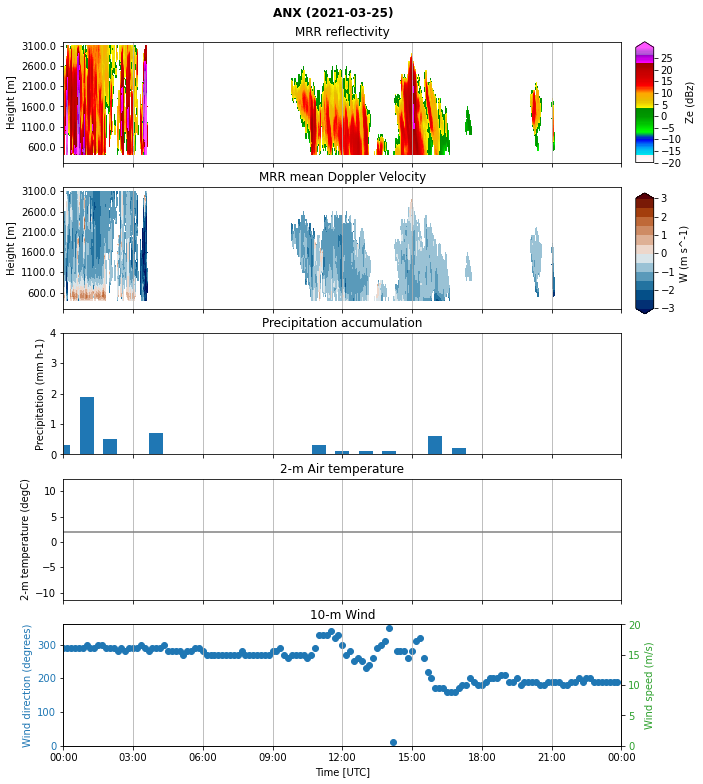

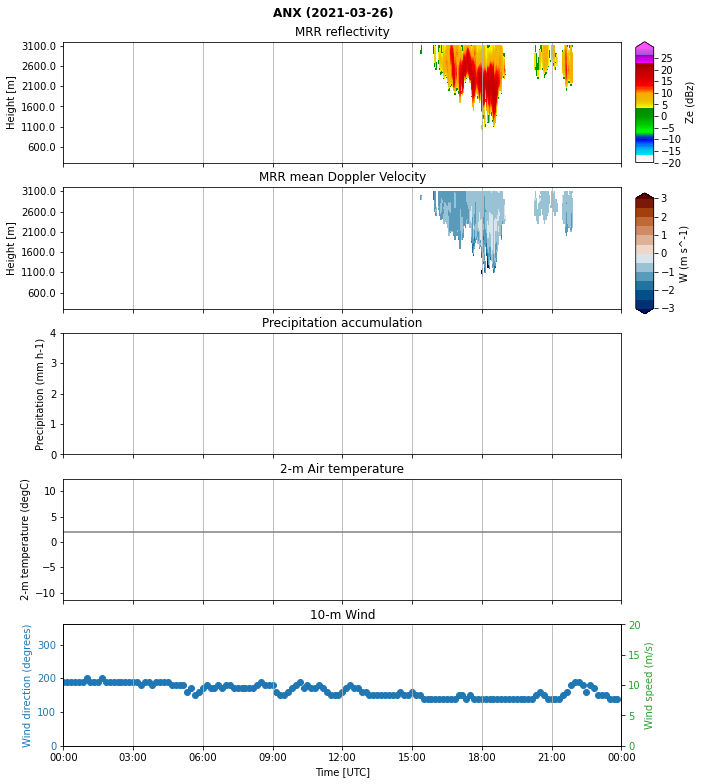

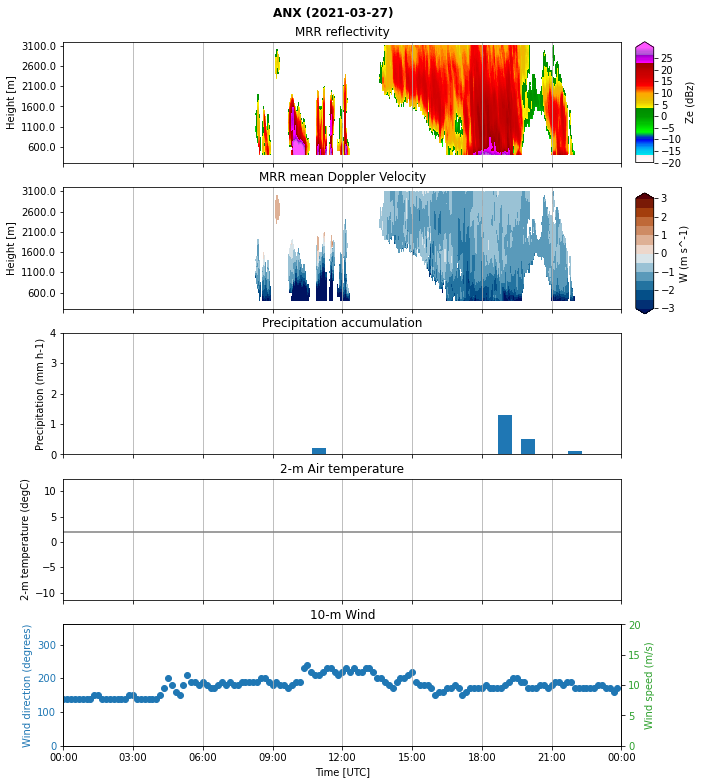

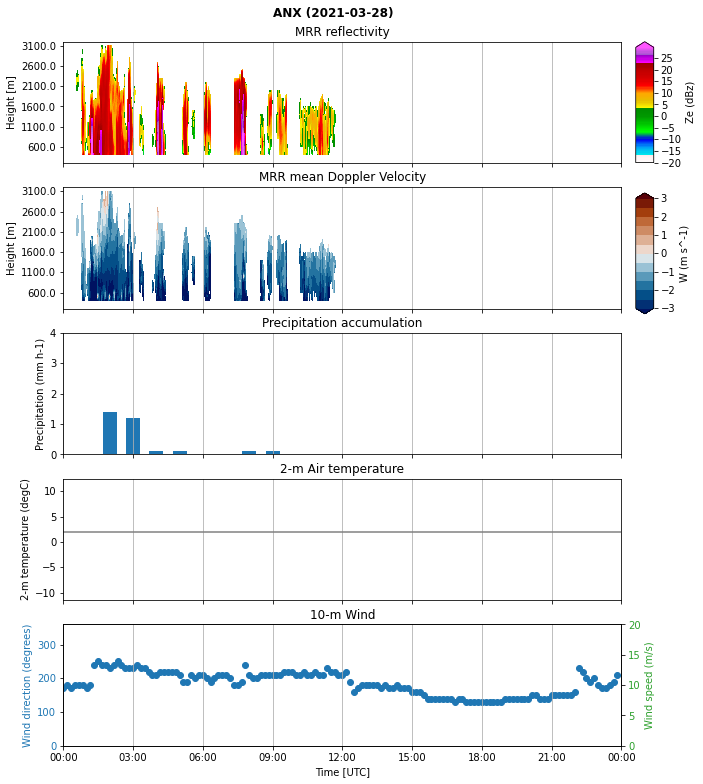

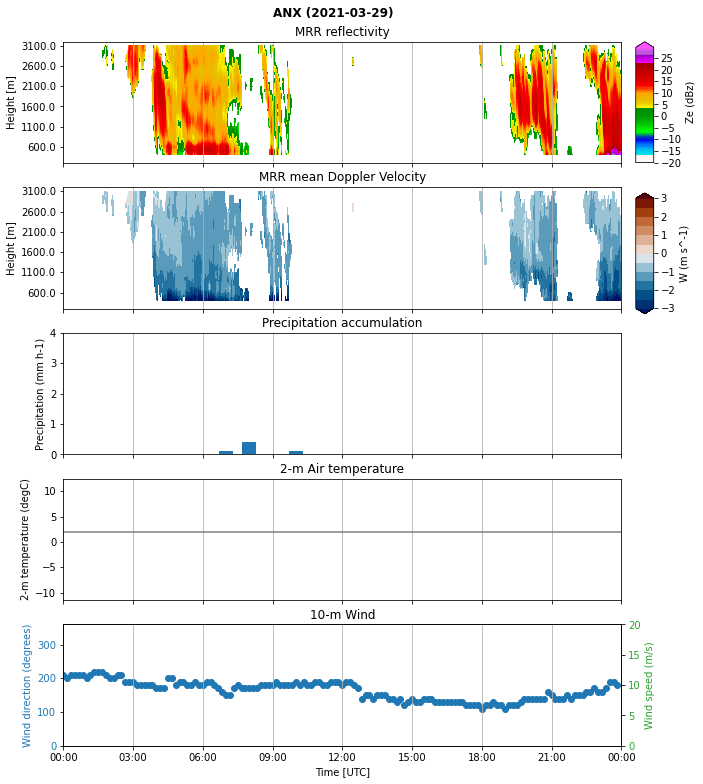

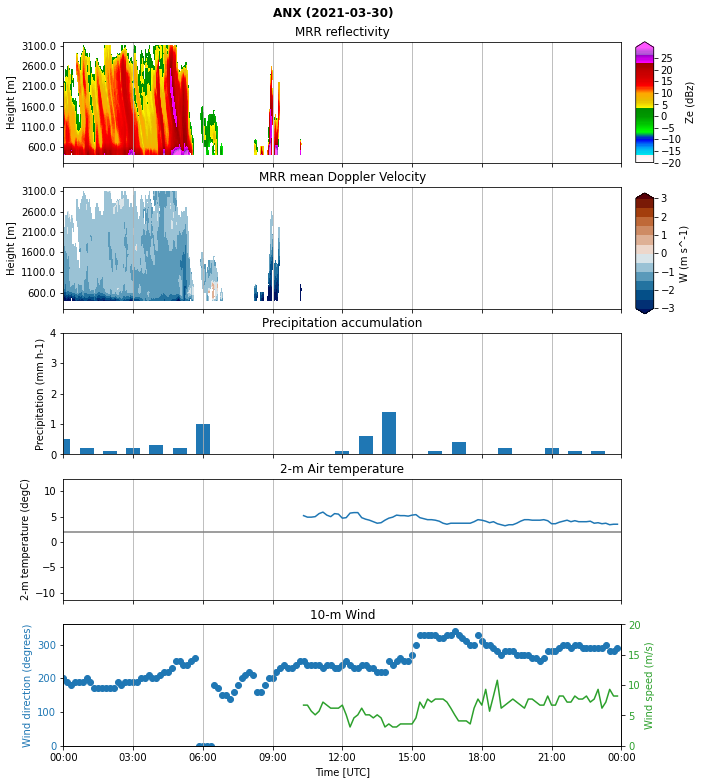

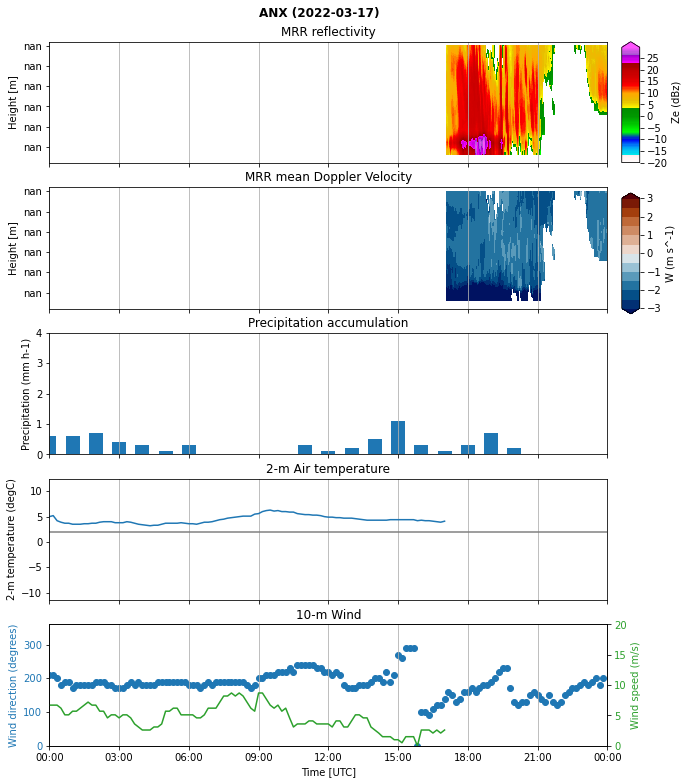

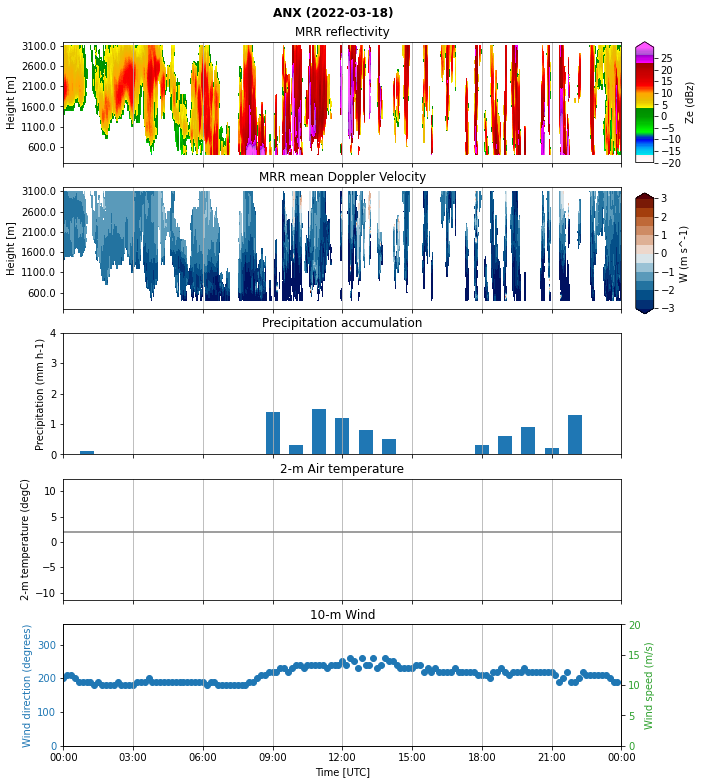

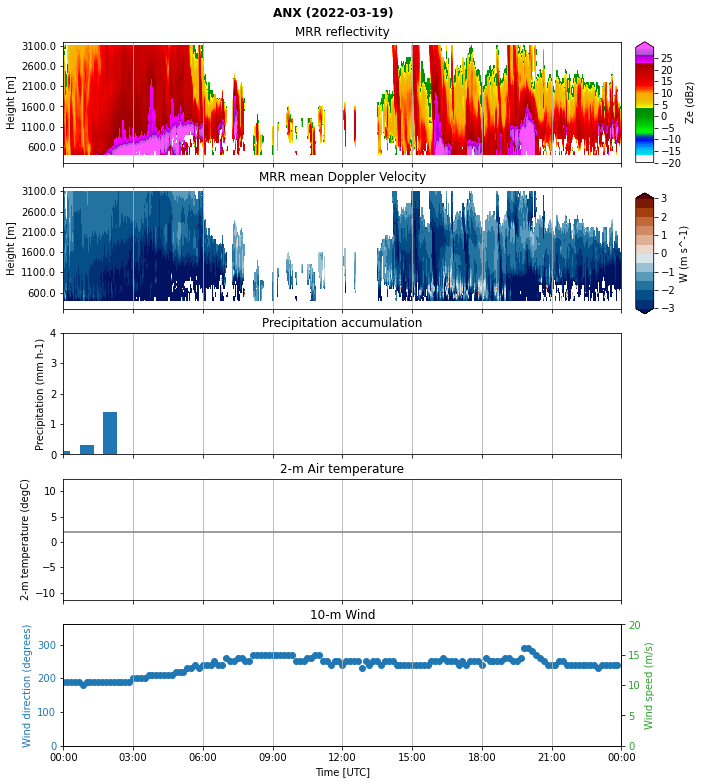

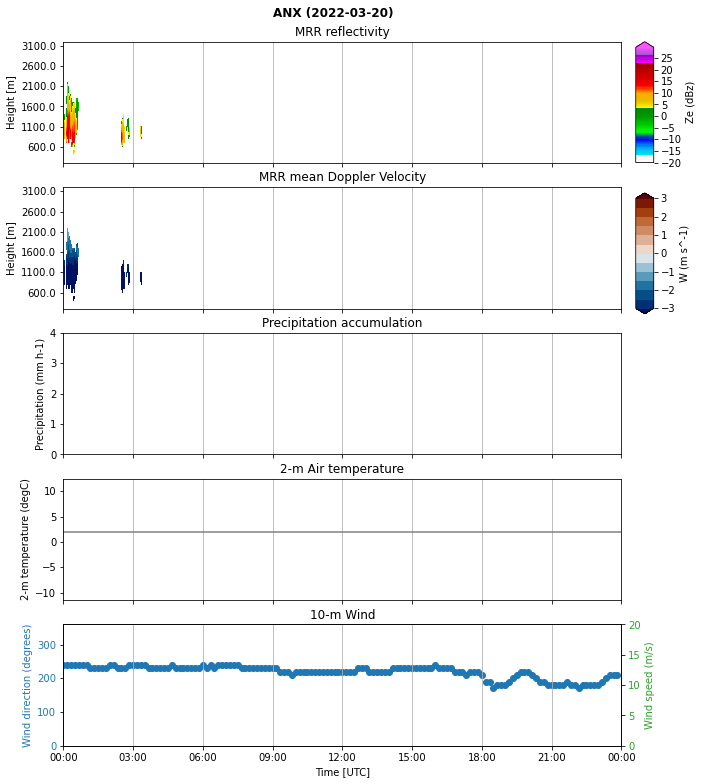

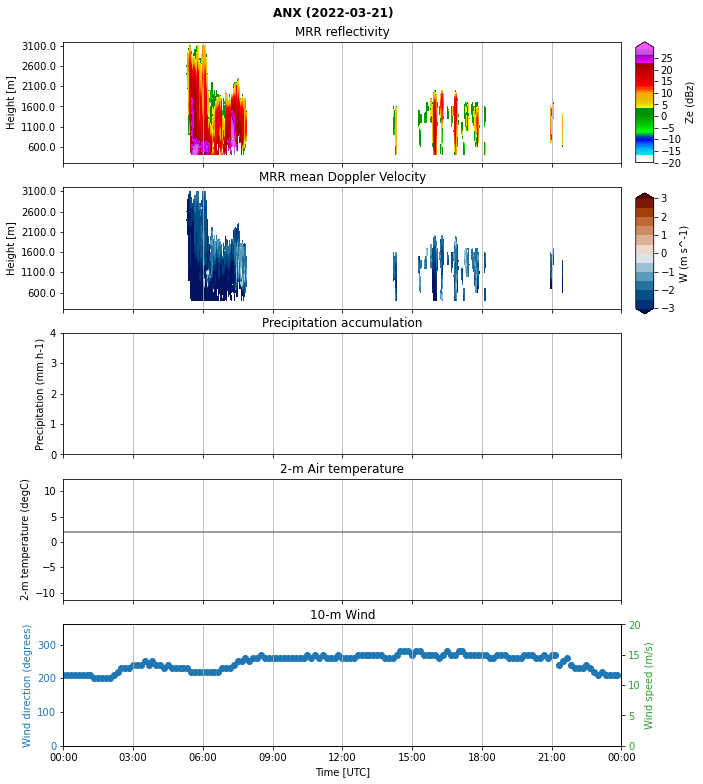

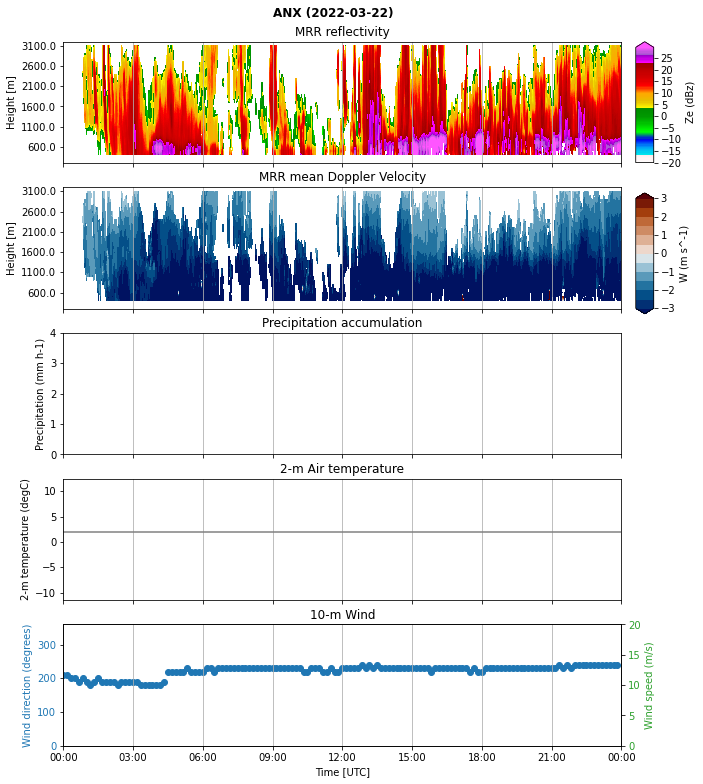

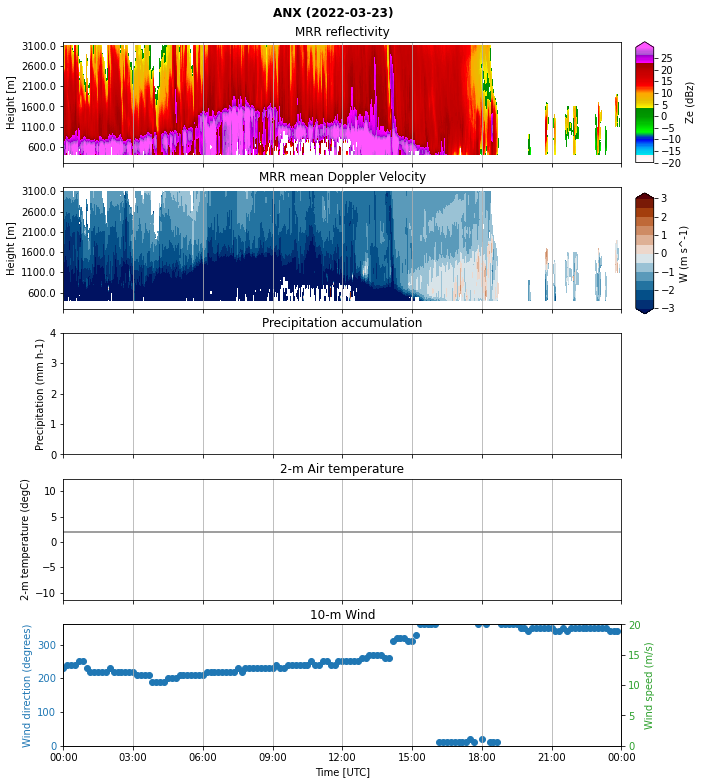

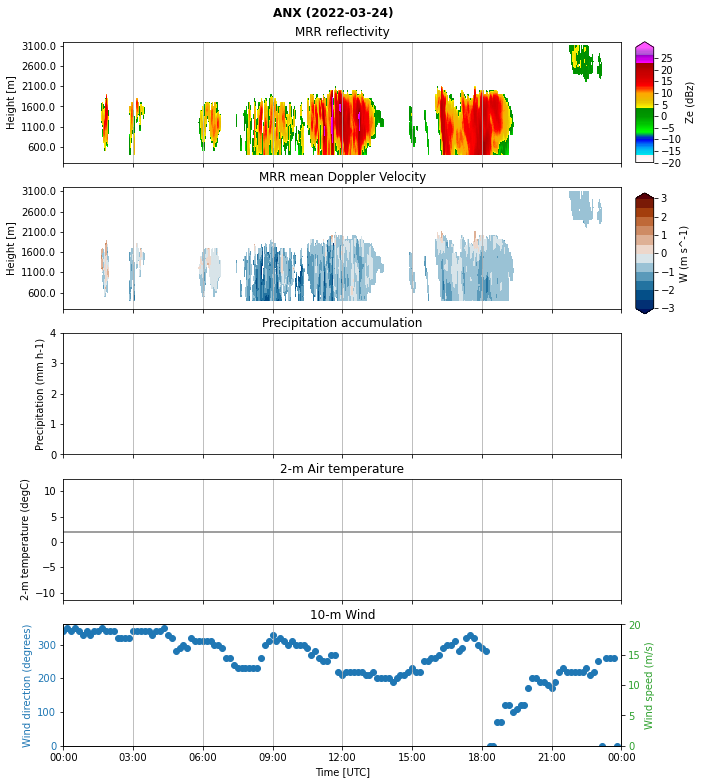

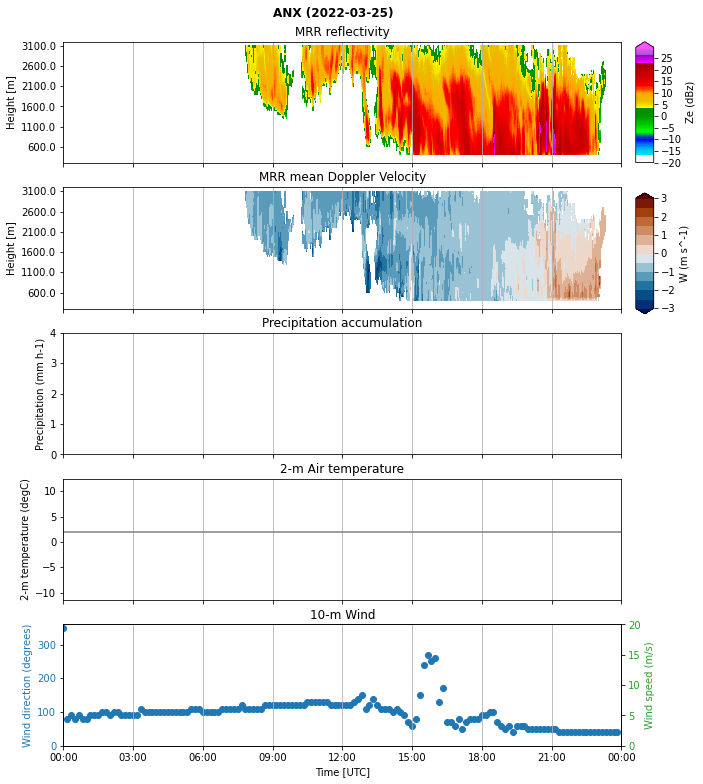

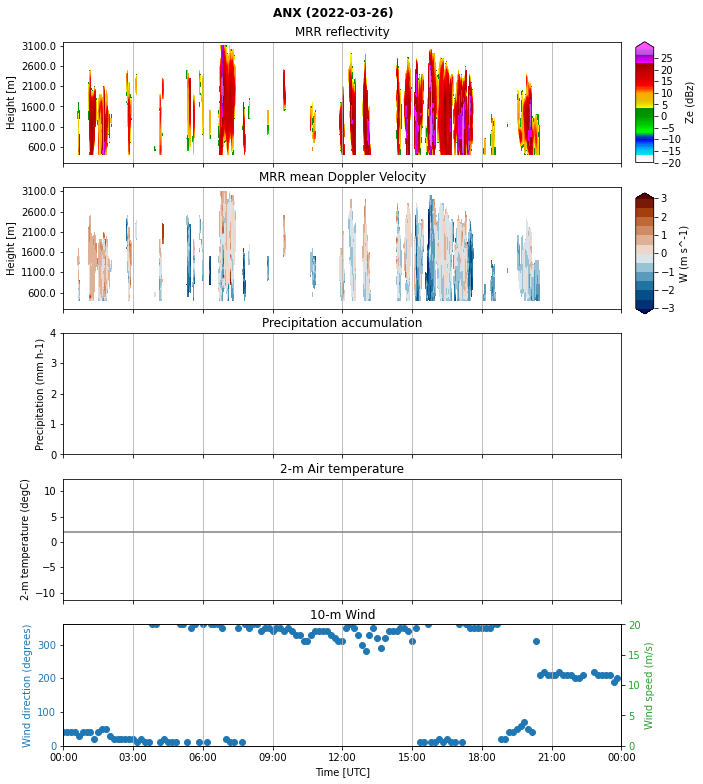

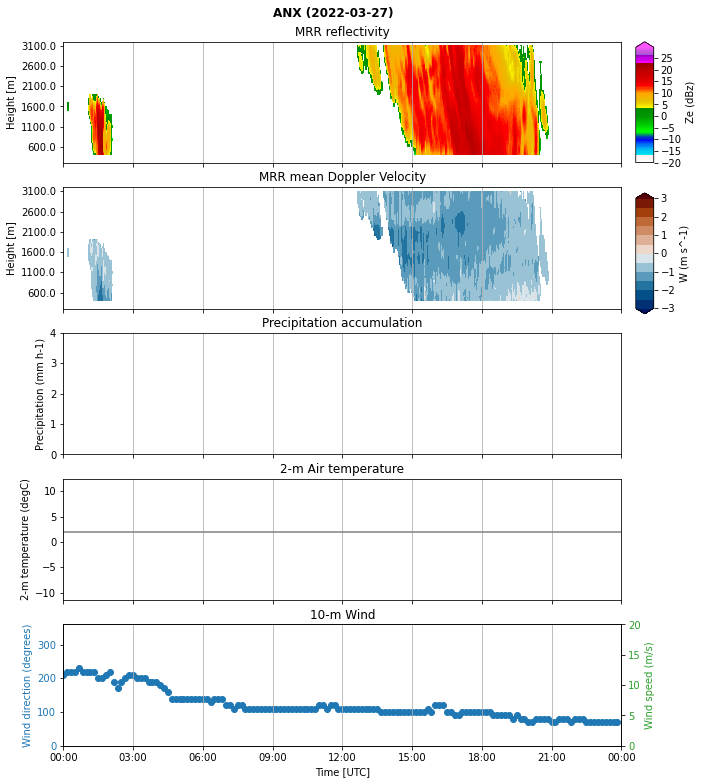

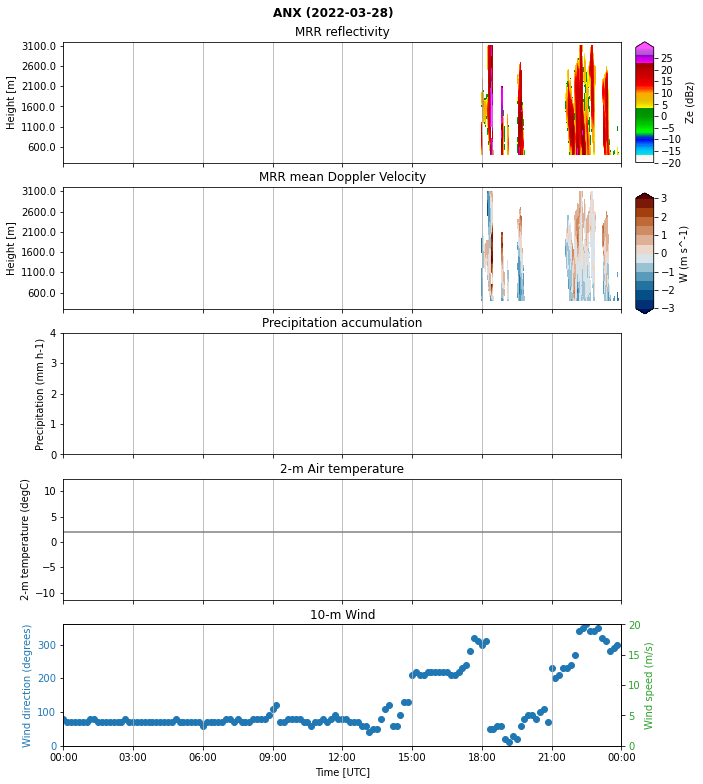

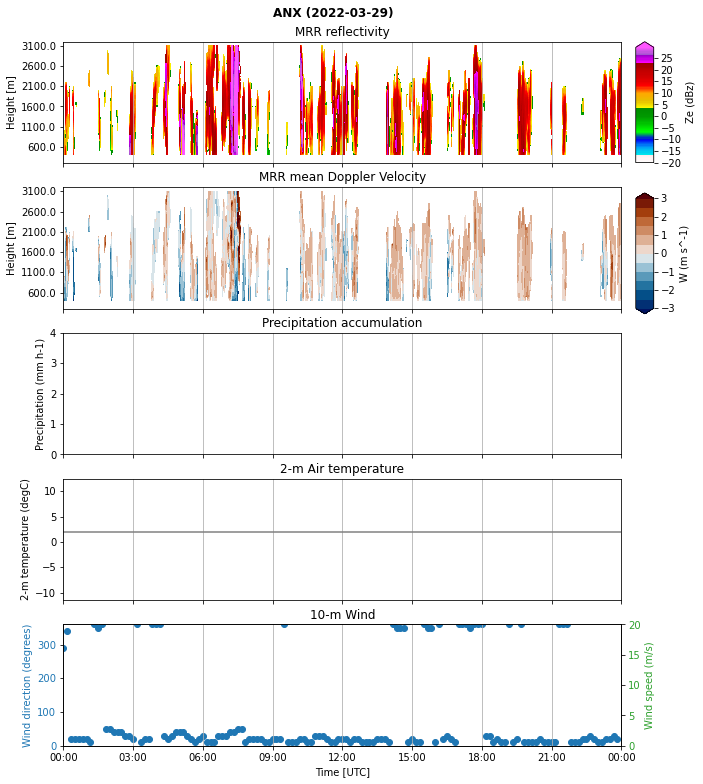

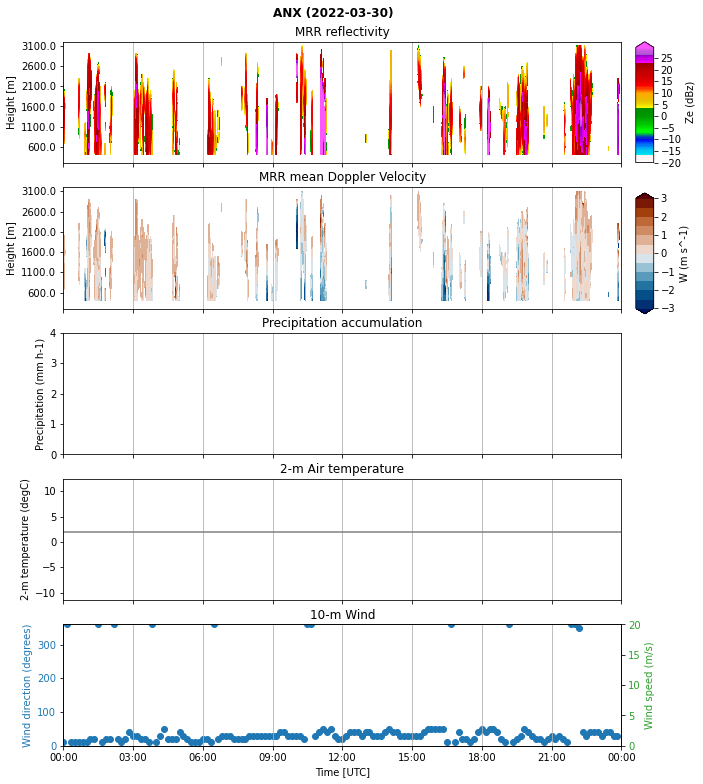

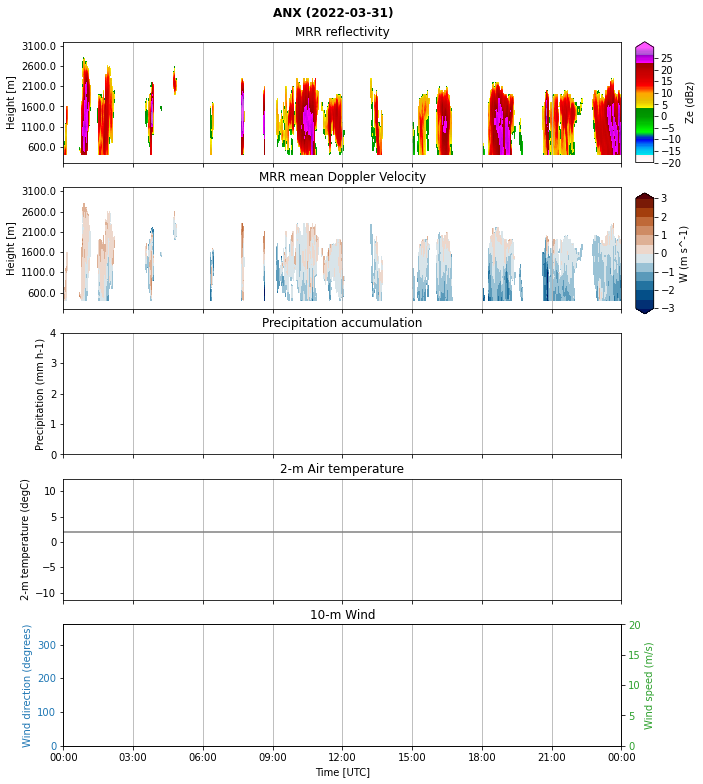

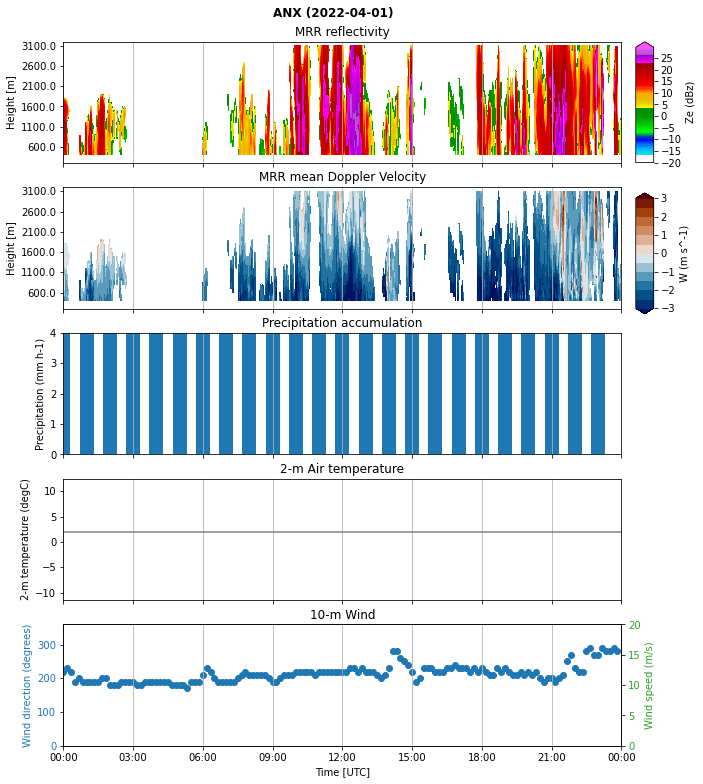

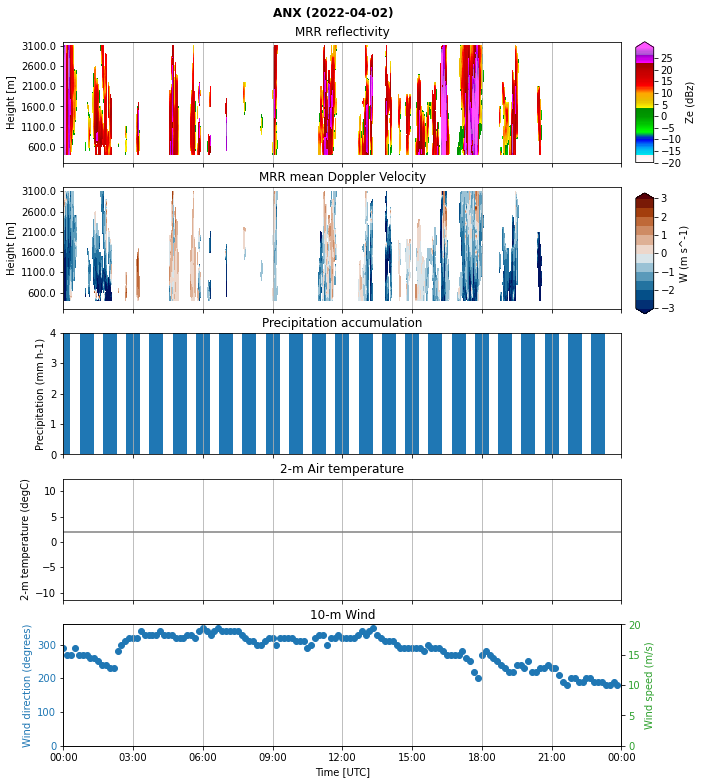

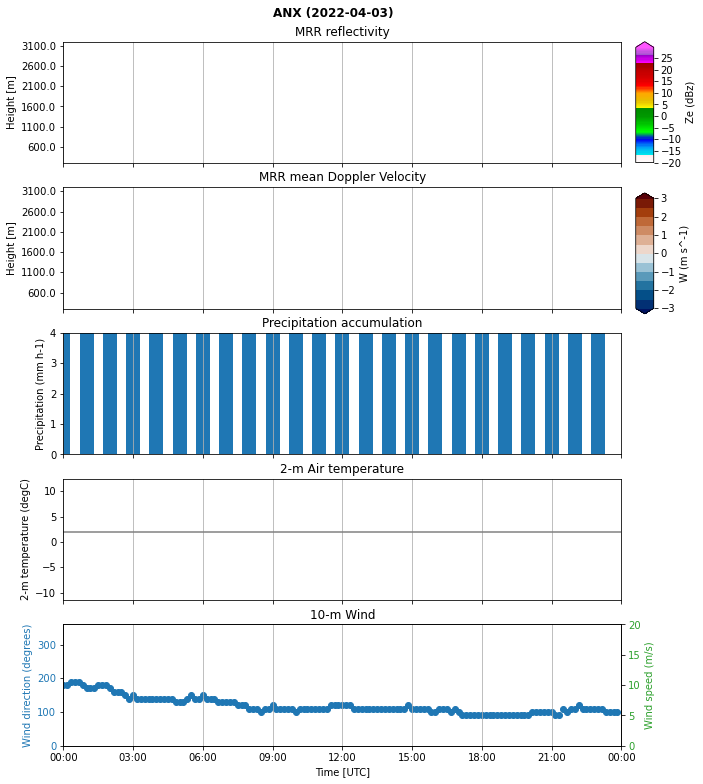

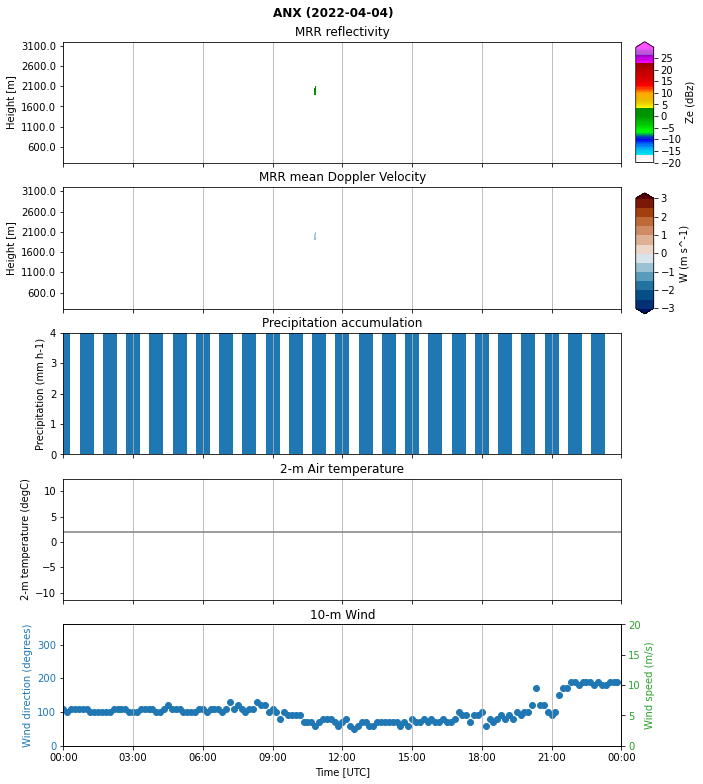

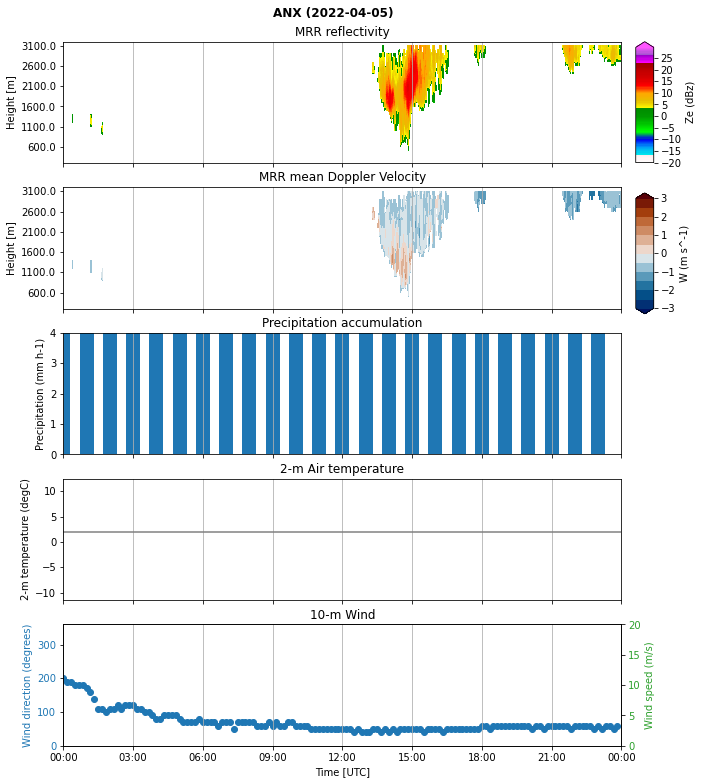

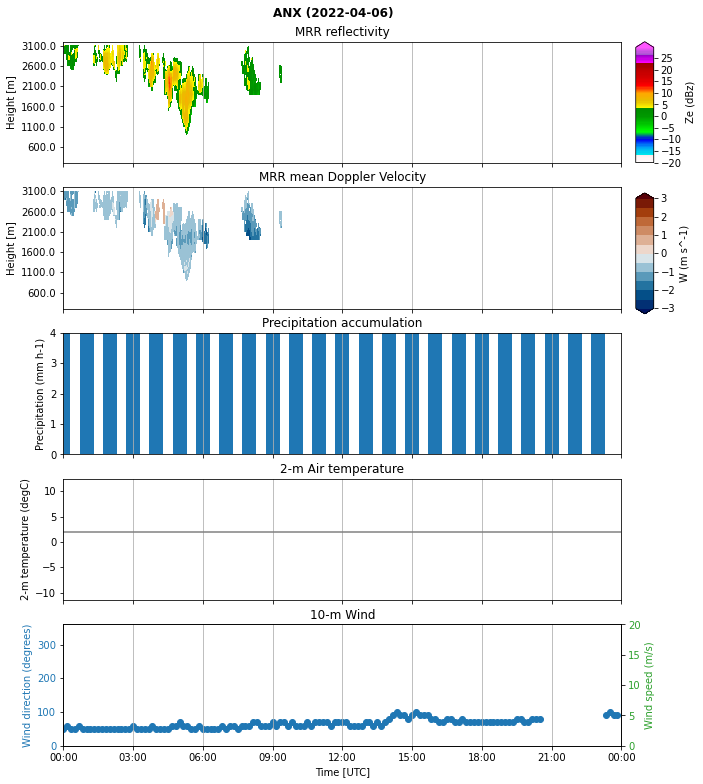

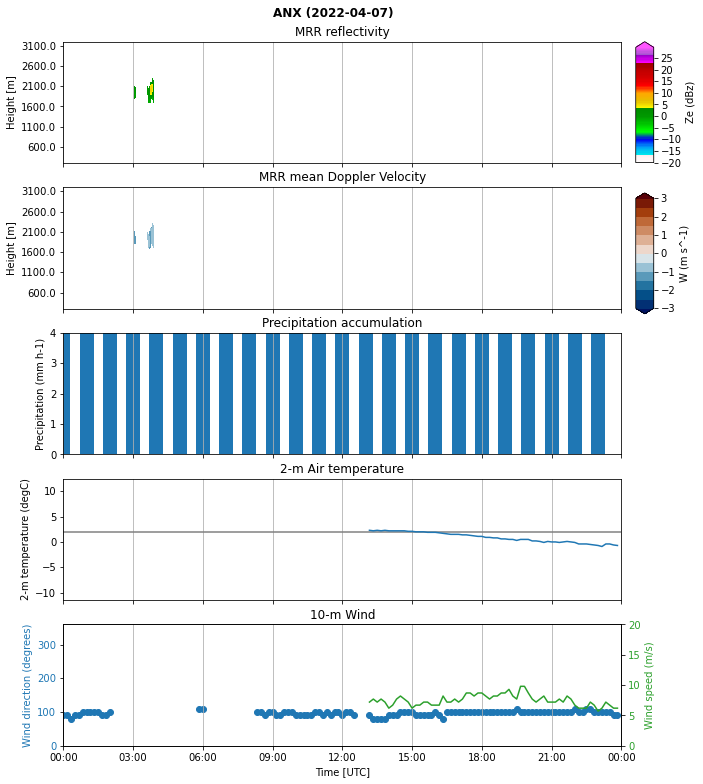

In [41]:

         
        # Define start and end time of individual day
        day_start = datetime.datetime.strptime("{} 00:00:00".format(date), '%Y%m%d %H:%M:%S').strftime('%Y-%m-%d %H:%M:%S')
        # print(day_start)
        day_end = (datetime.datetime.strptime("{} 00:00:00".format(date), '%Y%m%d %H:%M:%S') + datetime.timedelta(hours=23, minutes=59)).strftime('%Y-%m-%d %H:%M:%S')
        _xmax = (datetime.datetime.strptime(day_end, '%Y-%m-%d %H:%M:%S') + datetime.timedelta(minutes=1,)).strftime('%Y-%m-%d %H:%M:%S')

        # select Met-No data
        _air_temp = ds_dict_metno[key]['air_temperature'].sel(time = slice(day_start, day_end))
        _wd = ds_dict_metno[key]['wind_from_direction'].sel(time = slice(day_start, day_end))
        _ws = ds_dict_metno[key]['wind_speed'].sel(time = slice(day_start, day_end))
        _pp = ds_dict_metno[key]['sum(precipitation_amount PT1H)'].sel(time = slice(day_start, day_end))

        if _air_temp.size == 0:
                _air_temp = fct.dataarray_24hours(date, ds_dict_metno[key]['air_temperature'])
        if _wd.size == 0:
                _wd = fct.dataarray_24hours(date, ds_dict_metno[key]['wind_from_direction'])
        if _ws.size == 0:
                _ws = fct.dataarray_24hours(date, ds_dict_metno[key]['wind_speed'])
        if _pp.size == 0:
                _pp = fct.dataarray_24hours(date, ds_dict_metno[key]['sum(precipitation_amount PT1H)'])
        
        _pp = _pp.resample(time='1H').sum('time', skipna=True, keep_attrs=True)
        _pp = _pp.assign_attrs({'units':'mm h-1'})


        
        _Ze = ds_dict[key]['Ze'].sel(time = slice(day_start, day_end))
        _height = ds_dict[key]['height'].sel(time = slice(day_start, day_end))
        _W = (ds_dict[key]['W'].sel(time = slice(day_start, day_end)))*(-1)
        _W = _W.where(_Ze>=-20.)
        _W = _W.assign_attrs(ds_dict[key]['W'].attrs)


        try:
                _Ze.sel(time=_air_temp.time[0].values).time.size
        except KeyError:
                print(KeyError)
                _Ze = _Ze
                _height = _height
                _W = _W
        else:
                if _Ze.sel(time=_air_temp.time[0].values).time.size >1:
                        _l = _Ze.sel(time=_air_temp.time[0].values).time.size
                        _Ze = _Ze.isel(time=slice((_l-1), 1441))
                if _height.sel(time=_air_temp.time[0].values).time.size >1:
                        _l = _height.sel(time=_air_temp.time[0].values).time.size
                        _height = _height.isel(time=slice((_l-1), 1441))
                if _W.sel(time=_air_temp.time[0].values).time.size >1:
                        _l = _W.sel(time=_air_temp.time[0].values).time.size
                        _W = _W.isel(time=slice((_l-1), 1441))
        
        # create Dataset with all variables needed

        dsx = xr.combine_by_coords([_Ze, _W, _height, _air_temp, _pp, _wd, _ws])
        dsx = dsx.assign_attrs(attrs=ds_dict[key].attrs)
        dsx = dsx.assign_attrs({'title': 'Micro rain radar data processed with IMProToo and bin averaged'})

        fct.plt_Ze_W_p_T_U(dsx, day_start, _xmax, key)
        

In [ ]:
# save image to png
        plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True)


In [ ]:
### Make figure
        fig, axsm = plt.subplots(5, 1, figsize=[10,12], sharex=True, )
        axs = axsm.flatten()

        p1 = _Ze.plot.contourf(ax = axs[0], x='time', y='range', vmin = -20, 
                            levels = np.arange(-20, 30,0.5), 
                            cmap=plt.get_cmap('pymeteo_radar'), extend='max', add_colorbar=False,)
        cbaxes = fig.add_axes([0.92, 0.8, 0.025, 0.14])
        cbar = plt.colorbar(p1, cax=cbaxes, shrink=0.5, orientation='vertical')
        cbar.ax.set_ylabel('Ze ({})'.format(_Ze.attrs['units']))

        
        p2 = _W.plot.contourf(ax = axs[1], x='time', y='range',vmin=-3, vmax=3, 
                         levels=np.arange(-3,3.5,0.5), extend='both', cmap=cm.vik, add_colorbar=False,)
        cbaxes = fig.add_axes([0.92, 0.625, 0.025, 0.14])
        cbar = plt.colorbar(p2, cax=cbaxes, shrink=0.5, orientation='vertical')
        cbar.ax.set_ylabel('W ({})'.format(_W.attrs['units']))

        axs[2].bar(_pp['time'].values, _pp.values, width=0.025, align='center')
        axs[2].set_ylabel('Precipitation (mm h-1)')
        axs[2].set_ylim([0, 4])

        _air_temp.plot(ax = axs[3], x='time')
        axs[3].set_ylabel('2-m temperature ({})'.format(_air_temp.attrs['units']))
        axs[3].hlines(y= 2., xmin=day_start, xmax=_xmax, color = 'grey')
        axs[3].set_ylim([-11.5, 12.5])
        # axs[3].grid(axis='both')

        

        
        
        color = 'tab:blue'
        axs[4].scatter(x=_wd['time'].values, y =_wd.values, color=color,)
        axs[4].set_ylabel('Wind direction ({})'.format(_wd.attrs['units']),color=color, )
        axs[4].tick_params(axis='y', labelcolor=color)
        axs[4].set_ylim(0, 360)
        

        ax2 = axs[4].twinx()
        color = 'tab:green'
        _ws.plot(ax=ax2, x='time', color=color)
        ax2.set_ylabel('Wind speed ({})'.format(_ws.attrs['units']), color=color)
        ax2.tick_params(axis='y', labelcolor=color)
        ax2.set_ylim(0,20)

        
        
        # Define the date format
        date_form = DateFormatter("%H:00")
        for ax, tt in zip(axs,title):
            ax.set( xlabel = "",
                    title =tt)
            ax.xaxis.grid()
            ax.set_xlim([day_start, _xmax])
            ax.tick_params(axis='x', labelrotation=0, )
            plt.setp(ax.get_xticklabels(), horizontalalignment="center")
            ax.xaxis.set_major_formatter(date_form)
        for ax in axs[0:2]:
                ax.set(ylabel = "Height [m]", yticklabels=_height.isel(time=0).values[::5])
        
        
        

        axs[-1].set(xlabel = "Time [UTC]",)
            
        fig.suptitle("{} ({})".format(key.split('.')[0], _Ze.time.dt.date[0].values), fontweight="bold");
        fig.subplots_adjust(top=0.94)

        


        #####
        ## Average MRR variables in range bins
        # Radar equivalent reflectivity ($Ze$) in dBz is transformed to MRR radar reflectivity ($Z$) 
        # in $mm^6 m^{-3}$ by the following relationship:
        # # $$Ze = 10log_{10} (\frac{Z}{mm^6 m^{-3}})$$
        # # $$Z = 10^{Ze/10} mm^6 m^{-3}$$
        # # Once we know $Z$ it is possible to average over range sizes. The assumption is that the 4th 
        # range represents the bin between 300 and 400m and so on. Reflectivity, Doppler velocity, and height will 
        # be averaged in the bins (4,5), (6,7), (8,9), ... (26,27), (28,29), (30,31)
        

        _Ze_mean = xr.DataArray(data=da.full(shape = (len(_Ze.time),len(_Ze.range[1:-1][::2])), fill_value=np.nan), coords ={'time':_Ze.time.values, 'range':_Ze.range[1:-1][::2]})
        _W_mean = xr.DataArray(data=da.full(shape = (len(_W.time),len(_W.range[1:-1][::2])), fill_value=np.nan), coords={'time':_W.time.values, 'range':_W.range[1:-1][::2]})
        _height_mean = xr.DataArray(data=da.full(shape = (len(_height.time),len(_height.range[1:-1][::2])),fill_value=np.nan),coords={'time':_height.time.values, 'range':_height.range[1:-1][::2]})
        for i, k in zip(_Ze.range[1:-1][::2].values, range(len(_Ze.range[1:-1][::2]))):
                _Z = 10**(_Ze.sel(range=slice(i, (i+1)))/10)
                _Z_mean = _Z.mean('range', skipna=True, keep_attrs=True)
                _Ze_mean[:, k] = 10*np.log10(_Z_mean)

                _W_mean[:,k] = _W.sel(range=slice(i, (i+1))).mean('range', skipna=True, keep_attrs=True)
                _height_mean[:,k] = _height.sel(range=slice(i, (i+1))).mean('range', skipna=True, keep_attrs=True)

        _Ze_mean = _Ze_mean.assign_attrs(_Ze.attrs)
        _W_mean = _W_mean.assign_attrs(_W.attrs)
        _height_mean = _height_mean.assign_attrs(_height.attrs)

        # create dataset with all varibles
        dso = xr.Dataset(attrs=ds_dict[key].attrs)
        dso = dso.assign_attrs({'title': 'Micro rain radar data processed with IMProToo and bin averaged'})

        dso['Ze'] = _Ze_mean
        dso['W'] = _W_mean
        dso['height'] = _height_mean
        dso['2m_temperature'] = _air_temp
        dso['precipitation'] = _pp
        dso['wind_direction'] = _wd
        dso['wind_speed'] = _ws

        file_out = "{}_{}_{}_{}.nc".format(os.path.join(OUTPUT_DATA_DIR, 'MRR_islas/bin_averaged/mrr_improtoo'), version, site, date)
        dso.to_netcdf(file_out)

In [ ]:
# rsync -a --progress /home/franzihe/Documents/Figures/mrr_reflectivity notchpeak.chpc.utah.edu:/uufs/chpc.utah.edu/common/home/u6030275/public_html/Figures

In [ ]:
# rsync -a --progress login.nird.sigma2.no:/projects/NS9600K/sldam/timelapses_islas2022 /home/franzihe/Documents/Figures